# Notebook 04 - Pemodelan Baseline DDS vs noDDS

**Tahap penelitian:** Split data -> Random Forest, XGBoost, dan LightGBM pada dua varian fitur.

Notebook ini membandingkan pengaruh 10 fitur trik DDS dengan melatih Random Forest, XGBoost, dan LightGBM pada dataset DDS (174 fitur) serta noDDS (164 fitur). Dataset, label, dan split deal-aware sama; hanya fitur trik DDS yang berbeda. Semua model memakai konfigurasi yang sama per algoritma. Perbandingan validation dilaporkan di Notebook 05 dan test set dipakai sekali untuk membandingkan keenam baseline di Notebook 07.


## 0. Setup


In [15]:
import sys
import time
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

_root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _root_candidates if (p / "configs" / "config.yaml").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Tidak menemukan root repo (configs/config.yaml dan src/). Jalankan notebook dari repo atau folder notebooks.")
sys.path.insert(0, str(ROOT))

OUT       = ROOT / 'outputs' / 'results'
MODEL_DIR = ROOT / 'outputs' / 'models'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Sumber kebenaran hyperparameter — TIDAK di-hardcode di notebook (CLAUDE.md
# "Konvensi Kode"). RF & LightGBM sudah termasuk class_weight="balanced" di sini.
CONFIG = yaml.safe_load((ROOT / 'configs' / 'config.yaml').read_text())

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})
sns.set_palette('tab10')
print('Setup selesai. Hyperparameter dimuat dari configs/config.yaml.')


Setup selesai. Hyperparameter dimuat dari configs/config.yaml.


## 1. Muat Dataset DDS dan noDDS


In [16]:
from src.preprocessing import load_splits

DATASET_DIRS = {
    'DDS': ROOT / 'data' / 'processed',
    'noDDS': ROOT / 'data' / 'processed_no_dds',
}
splits_by_dataset = {}
feature_cols_by_dataset = {}
label_encoders = {}
for variant, data_dir in DATASET_DIRS.items():
    train_df, val_df, test_df, cols, label_encoder = load_splits(data_dir)
    splits_by_dataset[variant] = {'train': train_df, 'val': val_df, 'test': test_df}
    feature_cols_by_dataset[variant] = cols
    label_encoders[variant] = label_encoder

identity_cols = ['_source_file', '_room', '_board_number', '_deal_key', 'label', 'matches_par_contract']
for part in ('train', 'val', 'test'):
    assert splits_by_dataset['DDS'][part][identity_cols].equals(
        splits_by_dataset['noDDS'][part][identity_cols]
    ), f'Label atau split DDS/noDDS berbeda pada {part}'
assert len(feature_cols_by_dataset['DDS']) == 174
assert len(feature_cols_by_dataset['noDDS']) == 164
assert all(c.startswith(('ns_dd_', 'ew_dd_')) for c in
           [x for x in feature_cols_by_dataset['DDS'] if x not in feature_cols_by_dataset['noDDS']])
assert feature_cols_by_dataset['noDDS'] == [
    c for c in feature_cols_by_dataset['DDS'] if c in feature_cols_by_dataset['noDDS']
]

X_train_by_dataset = {
    variant: splits_by_dataset[variant]['train'][feature_cols_by_dataset[variant]].to_numpy(dtype=np.float32)
    for variant in DATASET_DIRS
}
X_val_by_dataset = {
    variant: splits_by_dataset[variant]['val'][feature_cols_by_dataset[variant]].to_numpy(dtype=np.float32)
    for variant in DATASET_DIRS
}
y_train = splits_by_dataset['noDDS']['train']['label'].to_numpy()
y_val = splits_by_dataset['noDDS']['val']['label'].to_numpy()
X_train = X_train_by_dataset['noDDS']  # diagnostik learning curve noDDS
le = label_encoders['noDDS']
assert np.array_equal(y_train, splits_by_dataset['DDS']['train']['label'].to_numpy())
assert np.array_equal(y_val, splits_by_dataset['DDS']['val']['label'].to_numpy())

n_total = len(splits_by_dataset['noDDS']['train']) + len(splits_by_dataset['noDDS']['val']) + len(splits_by_dataset['noDDS']['test'])
print(f'Dataset: {n_total:,} board | split train/val/test: '
      f'{len(splits_by_dataset["noDDS"]["train"]):,}/'
      f'{len(splits_by_dataset["noDDS"]["val"]):,}/'
      f'{len(splits_by_dataset["noDDS"]["test"]):,}')
print(f"DDS: {len(feature_cols_by_dataset['DDS'])} fitur | noDDS: {len(feature_cols_by_dataset['noDDS'])} fitur")
print(f'Label positif: {y_train.mean():.2%} train | {y_val.mean():.2%} validation')


Dataset: 50,227 board | split train/val/test: 35,161/7,534/7,532
DDS: 174 fitur | noDDS: 164 fitur
Label positif: 24.56% train | 24.57% validation


## 2. Definisi Model dan Hyperparameter

Ketiga model memakai konfigurasi dari `configs/config.yaml`. Random Forest dan LightGBM memakai `class_weight="balanced"` untuk menangani perbedaan proporsi kelas. XGBoost memakai parameter yang ditetapkan pada konfigurasi. Pemilihan baseline berdasarkan AP validation; metrik lain menjadi pendamping. Notebook 06 menguji variasi konfigurasi tambahan.


In [17]:
from src.models import RFModel, XGBModel, LGBMModel

# Semua hyperparameter dari configs/config.yaml (CONFIG, di sel setup).
# RF & LightGBM: class_weight="balanced" sudah ada di config.
# XGBoost: parameter diambil dari configs/config.yaml.
# Variasi konfigurasi dibandingkan di Notebook 06 menggunakan AP validation.
rf_cfg   = CONFIG['models']['random_forest']
xgb_cfg  = CONFIG['models']['xgboost']
lgbm_cfg = CONFIG['models']['lightgbm']

models = [
    RFModel(**rf_cfg),
    XGBModel(**xgb_cfg),
    LGBMModel(**lgbm_cfg),
]

print(f'{"Model":<15} Hyperparameter (configs/config.yaml)')
print('-' * 78)
for name, cfg in [('RandomForest', rf_cfg), ('XGBoost', xgb_cfg), ('LightGBM', lgbm_cfg)]:
    hp = ', '.join(f'{k}={v}' for k, v in cfg.items() if k not in ('random_state', 'n_jobs'))
    print(f'{name:<15} {hp}')


Model           Hyperparameter (configs/config.yaml)
------------------------------------------------------------------------------
RandomForest    n_estimators=300, max_depth=None, min_samples_split=5, class_weight=balanced
XGBoost         n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8
LightGBM        n_estimators=300, max_depth=-1, learning_rate=0.05, num_leaves=63, subsample=0.8, colsample_bytree=0.8, class_weight=balanced


## 3. Training


In [18]:
FORCE_RETRAIN = True

models_by_dataset = {}
train_times = {}

for variant in ('DDS', 'noDDS'):
    models_by_dataset[variant] = []
    for model_cls, cfg in ((RFModel, rf_cfg), (XGBModel, xgb_cfg), (LGBMModel, lgbm_cfg)):
        model = model_cls(**cfg)
        suffix = '_dds' if variant == 'DDS' else ''
        artifact = MODEL_DIR / f'{model.name.lower()}{suffix}.pkl'
        if not FORCE_RETRAIN and artifact.exists():
            with open(artifact, 'rb') as f:
                model = pickle.load(f)
            elapsed = None
            print(f'[LOAD] {variant:<5} {model.name:<14} <- {artifact.name}')
        else:
            if artifact.exists():
                artifact.unlink()
            print(f'[TRAIN] {variant:<5} {model.name:<14} ...', end=' ')
            t0 = time.time()
            model.fit(X_train_by_dataset[variant], y_train)
            elapsed = time.time() - t0
            model.save(artifact)
            print(f'{elapsed:.1f}s -> {artifact.name}')
        models_by_dataset[variant].append(model)
        train_times[(variant, model.name)] = elapsed

trained_models = [(variant, model) for variant in ('DDS', 'noDDS')
                  for model in models_by_dataset[variant]]
print('Enam baseline selesai disiapkan.')


[TRAIN] DDS   RandomForest   ... 12.6s -> randomforest_dds.pkl
[TRAIN] DDS   XGBoost        ... 4.8s -> xgboost_dds.pkl
[TRAIN] DDS   LightGBM       ... 3.8s -> lightgbm_dds.pkl
[TRAIN] noDDS RandomForest   ... 11.1s -> randomforest.pkl
[TRAIN] noDDS XGBoost        ... 4.8s -> xgboost.pkl
[TRAIN] noDDS LightGBM       ... 3.6s -> lightgbm.pkl
Enam baseline selesai disiapkan.


## 4. Perbandingan Model pada Validation Set


In [19]:
from src.evaluation import evaluate, print_summary

val_results_by_dataset = {}
all_val_results = []
for variant in ('DDS', 'noDDS'):
    results = []
    X_val_variant = X_val_by_dataset[variant]
    for model in models_by_dataset[variant]:
        y_pred = model.predict(X_val_variant)
        y_proba = model.predict_proba(X_val_variant)
        result = evaluate(y_val, y_pred, y_proba, le,
                          model_name=f'{model.name} ({variant})')
        results.append(result)
        all_val_results.append(result)
        print_summary(result)
    val_results_by_dataset[variant] = results



  RandomForest (DDS)
  Accuracy          : 0.8038
  Precision (macro) : 0.7389
  Recall (macro)    : 0.6906
  F1 (macro)        : 0.7075
  F1 (weighted)     : 0.7929
  F1 (positive)     : 0.5396
  ROC-AUC           : 0.7880
  PR-AUC (avg prec) : 0.6094

  XGBoost (DDS)
  Accuracy          : 0.8117
  Precision (macro) : 0.7658
  Recall (macro)    : 0.6748
  F1 (macro)        : 0.6987
  F1 (weighted)     : 0.7925
  F1 (positive)     : 0.5142
  ROC-AUC           : 0.7957
  PR-AUC (avg prec) : 0.6071

  LightGBM (DDS)
  Accuracy          : 0.7923
  Precision (macro) : 0.7221
  Recall (macro)    : 0.7350
  F1 (macro)        : 0.7279
  F1 (weighted)     : 0.7952
  F1 (positive)     : 0.5955
  ROC-AUC           : 0.8121
  PR-AUC (avg prec) : 0.6332

  RandomForest (noDDS)
  Accuracy          : 0.7653
  Precision (macro) : 0.6711
  Recall (macro)    : 0.6170
  F1 (macro)        : 0.6295
  F1 (weighted)     : 0.7436
  F1 (positive)     : 0.4051
  ROC-AUC           : 0.7148
  PR-AUC (avg prec) 

In [20]:
from src.evaluation import compare_models

val_df = compare_models(all_val_results)
print(f'=== Validation: tiga algoritma pada DDS (174) dan noDDS (164), {n_total:,} board ===')
display(val_df.style
    .format('{:.4f}')
    .highlight_max(color='#C8E6C9', axis=0)
    .set_caption('Semua model memakai split validation yang sama; hijau = terbaik per metrik'))


=== Validation: tiga algoritma pada DDS (174) dan noDDS (164), 50,227 board ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,f1_positive,roc_auc,average_precision
model,,,,,,,,
RandomForest (DDS),0.8038,0.7389,0.6906,0.7075,0.7929,0.5396,0.7880,0.6094
XGBoost (DDS),0.8117,0.7658,0.6748,0.6987,0.7925,0.5142,0.7957,0.6071
LightGBM (DDS),0.7923,0.7221,0.7350,0.7279,0.7952,0.5955,0.8121,0.6332
RandomForest (noDDS),0.7653,0.6711,0.6170,0.6295,0.7436,0.4051,0.7148,0.4704
XGBoost (noDDS),0.7712,0.6994,0.5729,0.5731,0.7210,0.2823,0.7115,0.4665
LightGBM (noDDS),0.7213,0.6373,0.6509,0.6425,0.7279,0.4747,0.7126,0.4590


## 5. Learning Curve (Performa vs Ukuran Data)

Analisis tambahan untuk melihat tren Average Precision saat ukuran data train bertambah. Cross-validation hanya memakai train set; konfigurasi ringkas di bagian ini bersifat diagnostik dan tidak menggantikan model baseline dari `configs/config.yaml` atau pemilihan kandidat pada validation.


In [21]:
RUN_LEARNING_CURVE = False  # True untuk menjalankan diagnostik CV yang melatih ulang model

if RUN_LEARNING_CURVE:
    from sklearn.model_selection import learning_curve
    from sklearn.ensemble import RandomForestClassifier
    from xgboost import XGBClassifier
    from lightgbm import LGBMClassifier

    train_sizes_abs = np.linspace(0.25, 1.0, 4)

    clf_configs = [
        ('Random Forest', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1, class_weight='balanced')),
        ('XGBoost',       XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=1, verbosity=0, eval_metric='logloss')),
        ('LightGBM',      LGBMClassifier(n_estimators=100, num_leaves=31, random_state=42, n_jobs=1, verbose=-1)),
    ]

    fig, ax = plt.subplots(figsize=(10, 6))
    colors_lc = ['#4472C4', '#ED7D31', '#70AD47']

    for (name, clf), color in zip(clf_configs, colors_lc):
        print(f'Learning curve: {name} ...', end=' ')
        t0 = time.time()
        train_sz, train_sc, val_sc = learning_curve(
            clf, X_train, y_train,
            train_sizes=train_sizes_abs,
            cv=3, scoring='average_precision',
            n_jobs=1,
        )
        print(f'{time.time()-t0:.0f}s')

        train_mean = train_sc.mean(axis=1)
        val_mean   = val_sc.mean(axis=1)
        val_std    = val_sc.std(axis=1)

        ax.plot(train_sz, train_mean, '--', color=color, alpha=0.6, lw=1.5)
        ax.plot(train_sz, val_mean,   '-',  color=color, lw=2.5, label=name)
        ax.fill_between(train_sz,
                        val_mean - val_std,
                        val_mean + val_std,
                        alpha=0.12, color=color)

    ax.set_title(f"Learning Curve noDDS ({len(feature_cols_by_dataset['noDDS'])} fitur) - Average Precision vs Ukuran Training Set", fontweight='bold')
    ax.set_xlabel('Ukuran Training Set (sampel)')
    ax.set_ylabel('Average Precision (PR-AUC)')
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig(OUT / 'nb04_learning_curve.png', bbox_inches='tight')
    plt.show()
else:
    print('Learning curve dilewati (diagnostik opsional; set RUN_LEARNING_CURVE=True untuk menjalankannya).')


Learning curve dilewati (diagnostik opsional; set RUN_LEARNING_CURVE=True untuk menjalankannya).


## 6. Performa dan Waktu Training


In [22]:
timing_results = []
for variant in ('DDS', 'noDDS'):
    for result in val_results_by_dataset[variant]:
        model_name = result['model'].replace(f' ({variant})', '')
        timing_results.append({
            'Dataset': variant,
            'Model': model_name,
            'Waktu (detik)': train_times[(variant, model_name)],
            'Val Accuracy': result['accuracy'],
        })
timing_df = pd.DataFrame(timing_results)
display(timing_df)


,Dataset,Model,Waktu (detik),Val Accuracy
0,DDS,RandomForest,12.564174,0.803823
1,DDS,XGBoost,4.846156,0.811654
2,DDS,LightGBM,3.766019,0.792275
3,noDDS,RandomForest,11.116927,0.765331
4,noDDS,XGBoost,4.806891,0.771171
5,noDDS,LightGBM,3.639359,0.721264


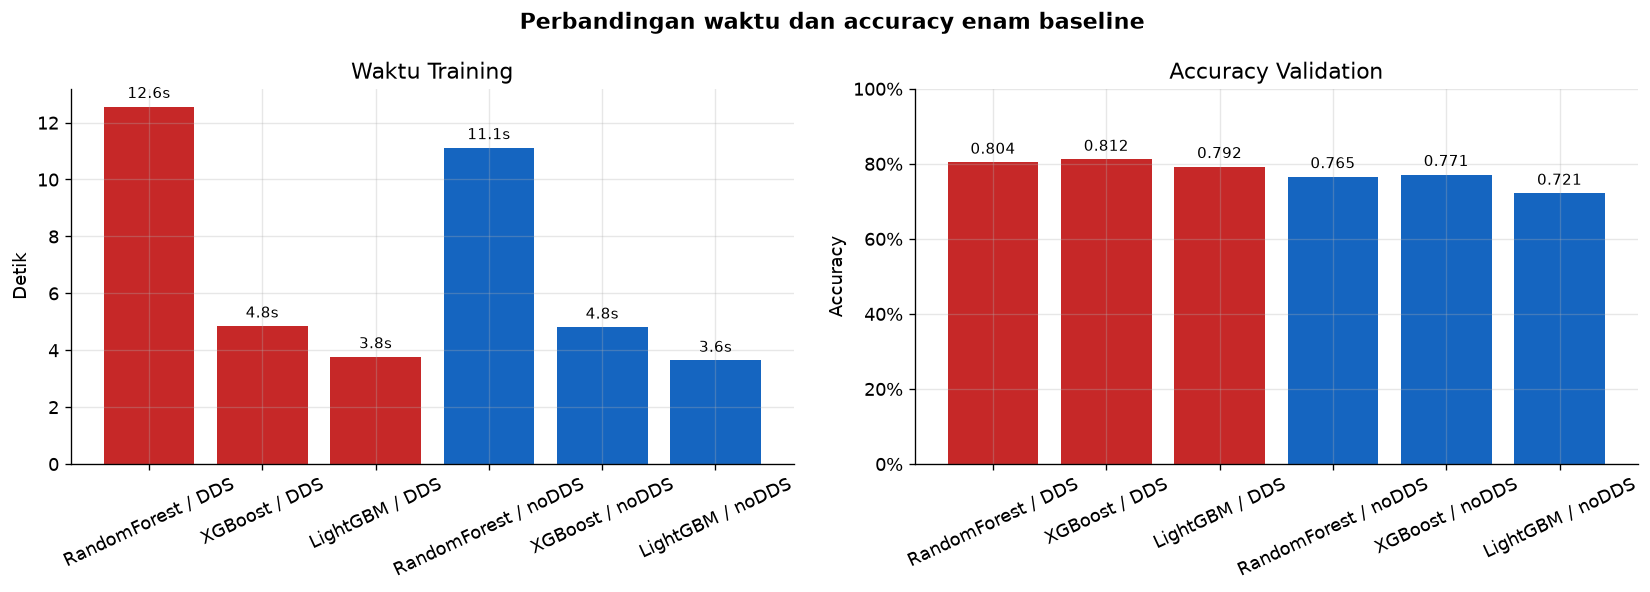

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_m = {'DDS': '#C62828', 'noDDS': '#1565C0'}
labels = [f"{r['Model']} / {r['Dataset']}" for r in timing_results]
bar_colors = [colors_m[r['Dataset']] for r in timing_results]

ax = axes[0]
bars = ax.bar(labels, [r['Waktu (detik)'] for r in timing_results], color=bar_colors)
ax.bar_label(bars, fmt='%.1fs', fontsize=9, padding=3)
ax.set_title('Waktu Training')
ax.set_ylabel('Detik')
ax.tick_params(axis='x', labelrotation=25)

ax = axes[1]
bars = ax.bar(labels, [r['Val Accuracy'] for r in timing_results], color=bar_colors)
ax.bar_label(bars, fmt='%.3f', fontsize=9, padding=3)
ax.set_title('Accuracy Validation')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.tick_params(axis='x', labelrotation=25)

fig.suptitle('Perbandingan waktu dan accuracy enam baseline', fontweight='bold')
fig.tight_layout()
plt.savefig(OUT / 'nb04_training_time_comparison.png', bbox_inches='tight')
plt.show()


In [24]:
import json
print('=' * 78)
print('RINGKASAN NOTEBOOK 04 - Baseline DDS vs noDDS')
print('=' * 78)
print(f"{'Model':<35} {'Acc':>8} {'F1 Macro':>10} {'ROC-AUC':>9} {'AP':>8} {'Waktu':>9}")
for result in all_val_results:
    pair = next(r for r in timing_results if result['model'] == f"{r['Model']} ({r['Dataset']})")
    elapsed = pair['Waktu (detik)']
    time_label = f'{elapsed:.1f}s' if elapsed is not None else 'loaded'
    print(f"{result['model']:<35} {result['accuracy']:>8.4f} "
          f"{result['f1_macro']:>10.4f} {result['roc_auc']:>9.4f} "
          f"{result['average_precision']:>8.4f} {time_label:>9}")
print('Lanjut ke Notebook 05 untuk analisis metrik dan SHAP per pasangan model.')

summary = {
    'datasets': {
        variant: {
            'n_features': len(feature_cols_by_dataset[variant]),
            'n_train': int(len(splits_by_dataset[variant]['train'])),
            'n_val': int(len(splits_by_dataset[variant]['val'])),
            'n_test': int(len(splits_by_dataset[variant]['test'])),
        }
        for variant in ('DDS', 'noDDS')
    },
    'same_labels_and_deal_aware_splits': True,
    'validation_results': [
        {k: v for k, v in result.items() if k not in ('per_class_report', 'confusion_matrix', 'class_names')}
        for result in all_val_results
    ],
}
(OUT / 'nb04_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Ringkasan pasangan DDS/noDDS disimpan ke nb04_summary.json.')


RINGKASAN NOTEBOOK 04 - Baseline DDS vs noDDS
Model                                    Acc   F1 Macro   ROC-AUC       AP     Waktu
RandomForest (DDS)                    0.8038     0.7075    0.7880   0.6094     12.6s
XGBoost (DDS)                         0.8117     0.6987    0.7957   0.6071      4.8s
LightGBM (DDS)                        0.7923     0.7279    0.8121   0.6332      3.8s
RandomForest (noDDS)                  0.7653     0.6295    0.7148   0.4704     11.1s
XGBoost (noDDS)                       0.7712     0.5731    0.7115   0.4665      4.8s
LightGBM (noDDS)                      0.7213     0.6425    0.7126   0.4590      3.6s
Lanjut ke Notebook 05 untuk analisis metrik dan SHAP per pasangan model.
Ringkasan pasangan DDS/noDDS disimpan ke nb04_summary.json.


## Ringkasan dan Tahap Berikutnya
Ketiga algoritma dilatih pada dua varian fitur dengan split identik. Notebook 05 membandingkan metrik dan SHAP; Notebook 06 berisi eksperimen tambahan pada noDDS.
